# RNN, LSTM, and BiLSTM for Time Series Forecasting
### Dataset: Beijing PM2.5 Air Pollution (2010–2014)

**Learning goals:** Understand why sequence models are useful; learn how RNN, LSTM, and BiLSTM work; prepare time series without leaking future data; and compare models against a simple baseline.

**Dataset location:** The notebook uses the Kaggle input path when available, then checks `data/` and `../data/` for the included CSV.

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.gridspec import GridSpec
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Works with both older and newer versions of scikit-learn.
try:
    from sklearn.metrics import root_mean_squared_error

    def rmse(y_true, y_pred):
        return root_mean_squared_error(y_true, y_pred)

except ImportError:
    def rmse(y_true, y_pred):
        return np.sqrt(mean_squared_error(y_true, y_pred))

from statsmodels.graphics.tsaplots import plot_acf

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11
})

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

Device: cpu


---
## Phase A — The problem and exploratory data analysis (EDA)

### Step 1 — Start with the simplest prediction

Before using neural networks, inspect the dataset and try a simple model. **Why?** A complex model is useful only if it improves on straightforward predictions.

Here the goal is to predict the **next hour’s PM2.5 pollution**. The first experiment compares a naive forecast (next hour = current hour) with linear regression using weather variables at the current hour.

In [2]:
KAGGLE_DATA_PATH = "/kaggle/input/datasets/rupakroy/lstm-datasets-multivariate-univariate/LSTM-Multivariate_pollution.csv"
LOCAL_DATA_PATHS = ["data/LSTM-Multivariate_pollution.csv", "../data/LSTM-Multivariate_pollution.csv"]
DATA_PATH = KAGGLE_DATA_PATH if os.path.exists(KAGGLE_DATA_PATH) else next(
    (path for path in LOCAL_DATA_PATHS if os.path.exists(path)), LOCAL_DATA_PATHS[0]
)
df = pd.read_csv(DATA_PATH)

print('Data path:', DATA_PATH)
print('Shape:', df.shape)
print('Columns:', df.columns.tolist())
print()
df.head()

Data path: LSTM-Multivariate_pollution.csv
Shape: (43800, 9)
Columns: ['date', 'pollution', 'dew', 'temp', 'press', 'wnd_dir', 'wnd_spd', 'snow', 'rain']



,date,pollution,dew,temp,press,wnd_dir,wnd_spd,snow,rain
0,2010-01-02 00:00:00,129.0,-16,-4.0,1020.0,SE,1.79,0,0
1,2010-01-02 01:00:00,148.0,-15,-4.0,1020.0,SE,2.68,0,0
2,2010-01-02 02:00:00,159.0,-11,-5.0,1021.0,SE,3.57,0,0
3,2010-01-02 03:00:00,181.0,-7,-5.0,1022.0,SE,5.36,1,0
4,2010-01-02 04:00:00,138.0,-7,-5.0,1022.0,SE,6.25,2,0


> **Output explained:** The CSV contains **43,800 hourly observations** and **9 original columns**. Each row records a date, pollution, and weather conditions. The first rows let us check that the data loaded correctly.

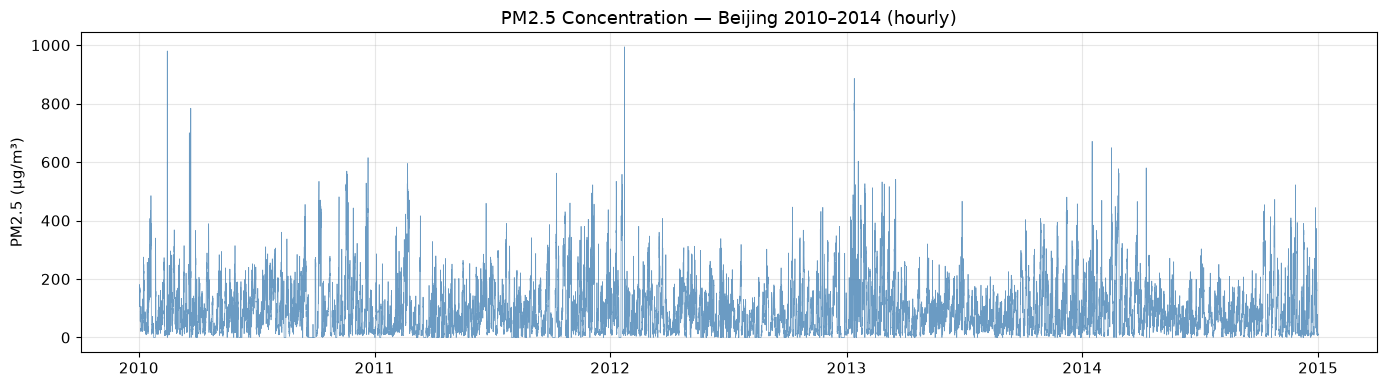

Rows: 43,800
Missing pollution: 0
PM2.5 range: 0 – 994 μg/m³


In [3]:
df['datetime'] = pd.to_datetime(df['date'])
df = df.sort_values('datetime').reset_index(drop=True)

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df['datetime'], df['pollution'], linewidth=0.5, color='steelblue', alpha=0.8)
ax.set_title('PM2.5 Concentration — Beijing 2010–2014 (hourly)', fontsize=13)
ax.set_ylabel('PM2.5 (μg/m³)')
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.tight_layout()
plt.show()

print(f'Rows: {len(df):,}')
print(f'Missing pollution: {df["pollution"].isna().sum()}')
print(f'PM2.5 range: {df["pollution"].min():.0f} – {df["pollution"].max():.0f} μg/m³')

> **Output explained:** The line graph shows how PM2.5 rises and falls over time. The file has **43,800 rows**, **zero missing pollution readings**, and values between **0 and 994 µg/m³**. Large peaks are important: a model may predict ordinary hours well but miss extreme pollution episodes.

=== INITIAL BASELINE COMPARISON ===
Naive forecast          | MAE=12.43  RMSE=24.51
Linear Regression naive | MAE=58.27  RMSE=84.38

If weather-only linear regression does not beat the naive forecast,
weather at time t alone is not enough; include historical observations.


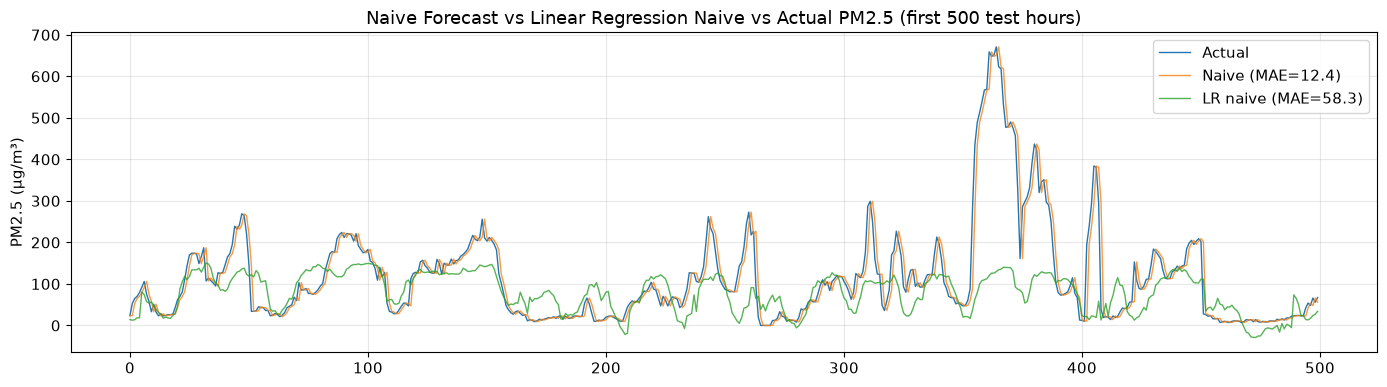

In [4]:
# Linear Regression naive — use only weather features at t to predict pollution(t+1)
# No past pollution values are provided.
# Goal: show that model complexity is not the main issue,
# but rather that the inputs are missing temporal information.

FEATURE_COLS = ['dew', 'temp', 'press', 'wnd_spd', 'snow', 'rain']

# Keep the shifted target separate so it does not confuse the missing-data analysis.
df_lr = df.copy()
df_lr['target'] = df_lr['pollution'].shift(-1)
df_model = df_lr[FEATURE_COLS + ['pollution', 'target', 'datetime']].dropna().reset_index(drop=True)

# Chronological split — DO NOT shuffle
split_idx = int(len(df_model) * 0.8)
X_train_lr = df_model[FEATURE_COLS].iloc[:split_idx]
y_train_lr = df_model['target'].iloc[:split_idx]
X_test_lr  = df_model[FEATURE_COLS].iloc[split_idx:]
y_test_lr  = df_model['target'].iloc[split_idx:]

# Model 1: Linear Regression naive — does not use past pollution
lr = LinearRegression()
lr.fit(X_train_lr, y_train_lr)
y_pred_lr = lr.predict(X_test_lr)

mae_lr  = mean_absolute_error(y_test_lr, y_pred_lr)
rmse_lr = rmse(y_test_lr, y_pred_lr)

# Model 0: Naive forecast — predict pollution(t+1) = pollution(t)
# This can be a strong baseline when consecutive values are highly correlated.
y_pred_naive_intro = df_model['pollution'].iloc[split_idx:].values
mae_naive_intro  = mean_absolute_error(y_test_lr, y_pred_naive_intro)
rmse_naive_intro = rmse(y_test_lr, y_pred_naive_intro)

print('=== INITIAL BASELINE COMPARISON ===')
print(f'Naive forecast          | MAE={mae_naive_intro:.2f}  RMSE={rmse_naive_intro:.2f}')
print(f'Linear Regression naive | MAE={mae_lr:.2f}  RMSE={rmse_lr:.2f}')
print()
print('If weather-only linear regression does not beat the naive forecast,')
print('weather at time t alone is not enough; include historical observations.')

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(y_test_lr.values[:500], label='Actual', linewidth=1)
ax.plot(y_pred_naive_intro[:500], label=f'Naive (MAE={mae_naive_intro:.1f})', linewidth=1, alpha=0.8)
ax.plot(y_pred_lr[:500], label=f'LR naive (MAE={mae_lr:.1f})', linewidth=1, alpha=0.8)
ax.set_title('Naive Forecast vs Linear Regression Naive vs Actual PM2.5 (first 500 test hours)')
ax.set_ylabel('PM2.5 (μg/m³)')
ax.legend()
plt.tight_layout()
plt.show()

> **Output explained:** The naive method reaches **MAE 12.43 / RMSE 24.51**, compared with **MAE 58.27 / RMSE 84.38** for weather-only linear regression. Smaller is better. The naive forecast wins by a large margin because recent pollution contains useful information that the regression inputs omit. The graph lets you see this: the naive line usually follows the actual line more closely than the regression line. These results do **not** show that all linear regression approaches are bad; lagged pollution features could make linear regression more competitive.

### What the first comparison teaches us

The naive forecast does much better than the weather-only linear regression in the saved run. This **does not** mean linear regression is always poor for time series. In this example, it was intentionally given no previous pollution measurements.

**Temporal dependency** means the next value depends on earlier values. Pollution at hour `t+1` often resembles pollution at hour `t`. To help a model learn this, we can add past values as **lag features** or pass the last several hours as a **sequence**.

**Decision:** Build 24-hour input windows and test models that understand sequences.

### Step 2 — EDA with a purpose

EDA means **Exploratory Data Analysis**: inspect data to decide how it should be prepared and modeled. Every plot should answer a question such as: Are values missing? Is there a repeating pattern? How much of the past might be useful? Which weather features might help?

In [5]:
# 2.1 — Missing values
# Check original dataset columns only.
# Creating a shifted target introduces a NaN in the final row; that is not an original missing value.
RAW_COLS = ['date', 'pollution', 'dew', 'temp', 'press', 'wnd_dir', 'wnd_spd', 'snow', 'rain']

print('Missing values in original columns:')
print(df[RAW_COLS].isnull().sum())
print()

if df[RAW_COLS].isnull().sum().sum() == 0:
    print('→ DECISION: No missing values in the original columns.')
else:
    print('→ DECISION: Handle missing values before making sliding windows.')

print('  The pipeline still uses forward fill for robustness if another version contains NaNs.')
print('  Avoid backward filling for online forecasting because it may use future information.')

Missing values in original columns:
date         0
pollution    0
dew          0
temp         0
press        0
wnd_dir      0
wnd_spd      0
snow         0
rain         0
dtype: int64

→ DECISION: No missing values in the original columns.
  The pipeline still uses forward fill for robustness if another version contains NaNs.
  Avoid backward filling for online forecasting because it may use future information.


> **Output explained:** Every original column shows **0 missing values**. No imputation is needed for this CSV. The code still keeps forward filling (`ffill`) as a safeguard for other versions of the data. Forward filling uses the last known value; backward filling could use a future measurement and is therefore inappropriate for an online prediction task.

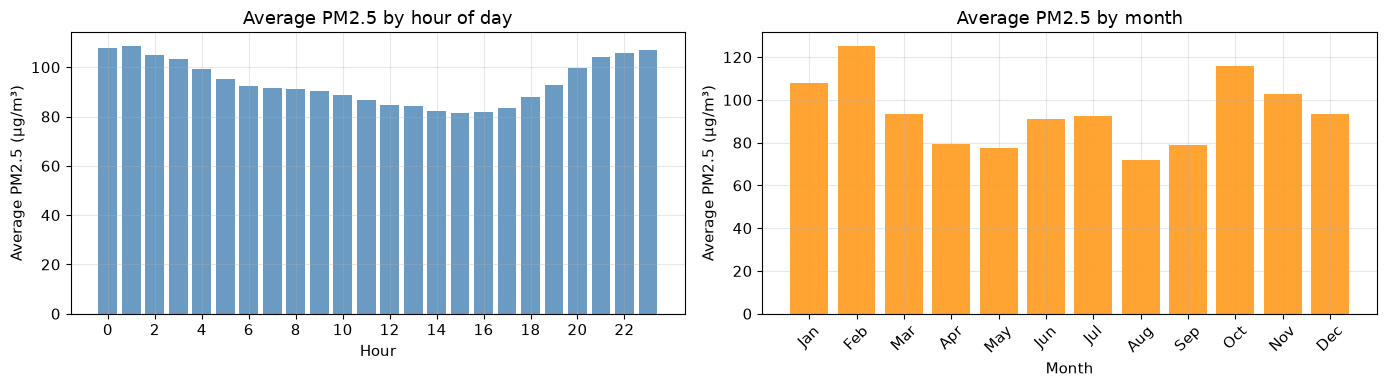

→ DECISION: PM2.5 shows seasonality, with higher levels in winter (Nov–Feb).
  Time-related patterns are present.
  Next, examine the ACF to guide the input window length.


In [6]:
# 2.2 — Seasonality by hour and month
df['hour']  = df['datetime'].dt.hour
df['month'] = df['datetime'].dt.month

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

hourly = df.groupby('hour')['pollution'].mean()
axes[0].bar(hourly.index, hourly.values, color='steelblue', alpha=0.8)
axes[0].set_title('Average PM2.5 by hour of day')
axes[0].set_xlabel('Hour')
axes[0].set_ylabel('Average PM2.5 (μg/m³)')
axes[0].set_xticks(range(0, 24, 2))

monthly = df.groupby('month')['pollution'].mean()
axes[1].bar(monthly.index, monthly.values, color='darkorange', alpha=0.8)
axes[1].set_title('Average PM2.5 by month')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Average PM2.5 (μg/m³)')
month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
axes[1].set_xticks(range(1,13))
axes[1].set_xticklabels(month_names, rotation=45)

plt.tight_layout()
plt.show()

print('→ DECISION: PM2.5 shows seasonality, with higher levels in winter (Nov–Feb).')
print('  Time-related patterns are present.')
print('  Next, examine the ACF to guide the input window length.')

> **Output explained:** The left graph compares **average pollution by hour of day**, and the right graph compares **average pollution by month**. The saved interpretation notes higher pollution in winter, particularly around **November–February**. This suggests repeating seasonal patterns. Monthly patterns alone do not tell us the best history length; we examine autocorrelation next.

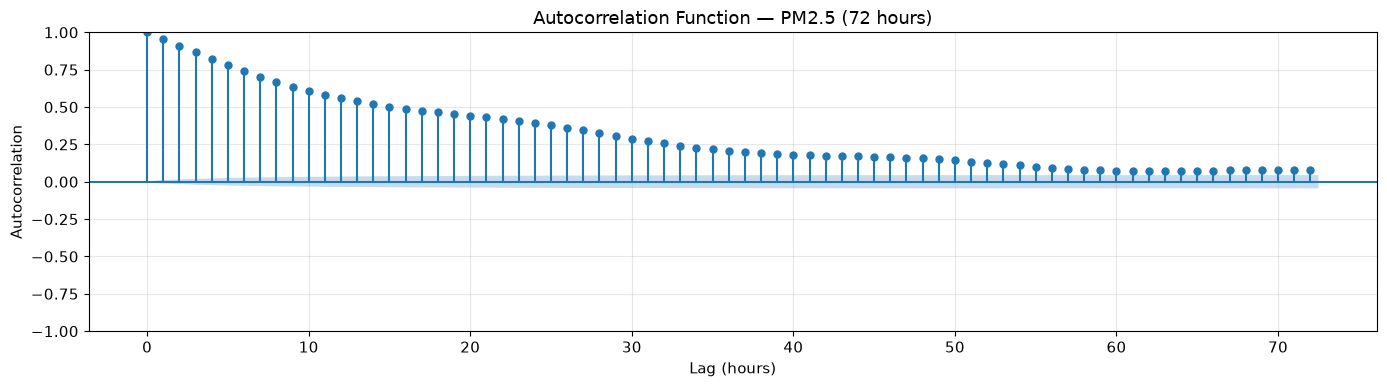

→ DECISION: High, slowly declining ACF means several past hours matter.
  ACF remains noticeable at lags 24 and 48, suggesting daily structure.
  → Start with window_size = 24 (one day).


In [7]:
# 2.3 — ACF: measure how PM2.5(t) relates to its past values PM2.5(t-k)
fig, ax = plt.subplots(figsize=(14, 4))
plot_acf(df['pollution'].values, lags=72, ax=ax, alpha=0.05)
ax.set_title('Autocorrelation Function — PM2.5 (72 hours)')
ax.set_xlabel('Lag (hours)')
ax.set_ylabel('Autocorrelation')
plt.tight_layout()
plt.show()

print('→ DECISION: High, slowly declining ACF means several past hours matter.')
print('  ACF remains noticeable at lags 24 and 48, suggesting daily structure.')
print('  → Start with window_size = 24 (one day).')

> **Output explained:** The ACF plot asks: **How related is pollution now to pollution 1, 2, ... 72 hours ago?** A high bar indicates a strong relationship at that lag. The saved analysis reports slowly declining autocorrelation and noticeable values around **24 and 48 hours**. A **24-hour window** is a reasonable first choice, not necessarily the mathematically best one.

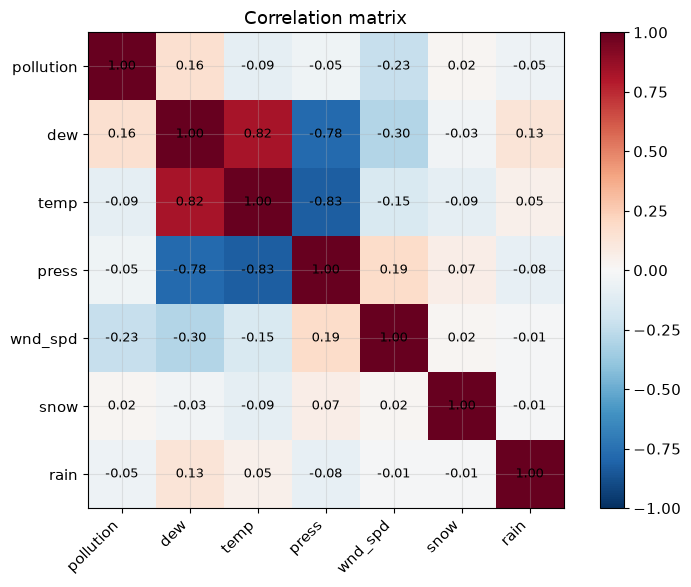

Correlation with pollution (sorted by absolute r):
  wnd_spd : -0.234
  dew     : +0.158
  temp    : -0.091
  rain    : -0.049
  press   : -0.046
  snow    : +0.022

→ DECISION: wind speed has the strongest (negative) linear weather correlation.
  Dew point and temperature show weak correlations; weather correlations are generally modest.
  A multivariate model may help, but a large gain is not guaranteed.
  We test added weather inputs in Step 8.


In [8]:
# 2.4 — Correlation PM2.5 vs weather features
num_cols = ['pollution', 'dew', 'temp', 'press', 'wnd_spd', 'snow', 'rain']
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
plt.colorbar(im, ax=ax)
ax.set_xticks(range(len(num_cols)))
ax.set_yticks(range(len(num_cols)))
ax.set_xticklabels(num_cols, rotation=45, ha='right')
ax.set_yticklabels(num_cols)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        ax.text(j, i, f'{corr.iloc[i,j]:.2f}', ha='center', va='center', fontsize=9)
ax.set_title('Correlation matrix')
plt.tight_layout()
plt.show()

pm25_corr = corr['pollution'].drop('pollution').sort_values(key=abs, ascending=False)
print('Correlation with pollution (sorted by absolute r):')
for feat, val in pm25_corr.items():
    print(f'  {feat:8s}: {val:+.3f}')
print()
print('→ DECISION: wind speed has the strongest (negative) linear weather correlation.')
print('  Dew point and temperature show weak correlations; weather correlations are generally modest.')
print('  A multivariate model may help, but a large gain is not guaranteed.')
print('  We test added weather inputs in Step 8.')

> **Output explained:** Each heatmap cell gives the correlation between two numerical variables. The strongest weather correlation with pollution is **wind speed: −0.234** (higher wind often goes with lower pollution). Dew point is **+0.158** and temperature **−0.091**; the others are even closer to zero. All are modest linear correlations. Correlation is **not causation**, and weak individual correlations do not rule out useful nonlinear combinations.

---
## Phase B — Preprocessing and sliding windows

### Step 3 — Prepare the data

This pipeline converts raw observations into model-ready numbers. The order matters: sort by time, handle missing entries, encode wind direction, split by date, and fit scaling **only on training data**.

**Data leakage** means accidentally giving the model information from the future. It leads to misleadingly good test scores.

In [9]:
df_proc = df.copy()

# --- Step 1: parse timestamps and sort ---
# The datetime column was created and sorted in Phase A.
assert df_proc['datetime'].is_monotonic_increasing, 'Data must be sorted by time before preprocessing.'

# --- Step 2: handle missing values ---
# For time series, handle missing values without leaking future information.
# This cleaned dataset has no NaNs, but the tutorial still checks.
BASE_NUM_COLS = ['pollution', 'dew', 'temp', 'press', 'wnd_spd', 'snow', 'rain']
BASE_CAT_COLS = ['wnd_dir']

print('Missing before preprocessing:')
print(df_proc[BASE_NUM_COLS + BASE_CAT_COLS].isna().sum())

# Forward fill uses the most recent past value, which is reasonable for hourly data.
# If the first rows remain NaN, drop them instead of backward filling.
df_proc[BASE_NUM_COLS] = df_proc[BASE_NUM_COLS].ffill()
df_proc[BASE_CAT_COLS] = df_proc[BASE_CAT_COLS].ffill()
df_proc = df_proc.dropna(subset=BASE_NUM_COLS + BASE_CAT_COLS).reset_index(drop=True)

print('\nMissing after preprocessing:')
print(df_proc[BASE_NUM_COLS + BASE_CAT_COLS].isna().sum())

# --- Step 3: encode wind direction using sine and cosine ---
# wnd_dir is categorical: 'SE', 'NW', 'NE', 'cv' (calm/variable)
# Wind direction is circular, so sine/cosine helps preserve angular relationships.
# But 'cv' is calm/variable, not angle zero, so give it a separate indicator.
print('\nWind direction values:', df_proc['wnd_dir'].unique())

wind_to_angle = {
    'NE': 45,
    'SE': 135,
    'SW': 225,
    'NW': 315,
}

df_proc['wind_is_cv'] = (df_proc['wnd_dir'] == 'cv').astype(int)
df_proc['wind_angle'] = df_proc['wnd_dir'].map(wind_to_angle)

# Reject unknown wind categories explicitly rather than silently generating NaN.
unknown_wind = sorted(set(df_proc['wnd_dir'].dropna().unique()) - set(wind_to_angle.keys()) - {'cv'})
assert len(unknown_wind) == 0, f'Unhandled wind direction categories: {unknown_wind}'

df_proc['wind_sin'] = np.sin(np.deg2rad(df_proc['wind_angle']))
df_proc['wind_cos'] = np.cos(np.deg2rad(df_proc['wind_angle']))

# For 'cv', set sine/cosine to zero and wind_is_cv=1 to mark it as non-directional.
df_proc[['wind_sin', 'wind_cos']] = df_proc[['wind_sin', 'wind_cos']].fillna(0)

# --- Step 4: select features ---
# Target is always 'pollution' (column index 0).
UNI_COLS   = ['pollution']
MULTI_COLS = [
    'pollution', 'dew', 'temp', 'press', 'wnd_spd', 'snow', 'rain',
    'wind_sin', 'wind_cos', 'wind_is_cv'
]

assert df_proc[MULTI_COLS].isna().sum().sum() == 0, 'Missing values remain in the feature matrix.'

print(f'\nUnivariate features : {UNI_COLS}')
print(f'Multivariate features: {MULTI_COLS}')
print(f'n_features multivariate = {len(MULTI_COLS)}')


Missing before preprocessing:
pollution    0
dew          0
temp         0
press        0
wnd_spd      0
snow         0
rain         0
wnd_dir      0
dtype: int64

Missing after preprocessing:
pollution    0
dew          0
temp         0
press        0
wnd_spd      0
snow         0
rain         0
wnd_dir      0
dtype: int64

Wind direction values: <StringArray>
['SE', 'cv', 'NW', 'NE']
Length: 4, dtype: str

Univariate features : ['pollution']
Multivariate features: ['pollution', 'dew', 'temp', 'press', 'wnd_spd', 'snow', 'rain', 'wind_sin', 'wind_cos', 'wind_is_cv']
n_features multivariate = 10


> **Output explained:** Missing-value counts remain **zero** before and after preprocessing. Observed wind directions are `SE`, `cv`, `NW`, and `NE`. Circular directions are represented by sine/cosine, while `cv` (calm/variable) gets its own indicator. The final univariate input has **1 feature**; multivariate input has **10 features**.

In [10]:
# --- Step 5: chronological train/test split ---

# ⚠️ Never shuffle a time series when splitting into train/test.
# Shuffling may place later test-period data into training.
# → The model indirectly sees the future, giving misleading scores.

TRAIN_RATIO = 0.8
split_idx = int(len(df_proc) * TRAIN_RATIO)

df_train = df_proc.iloc[:split_idx].copy()
df_test  = df_proc.iloc[split_idx:].copy()

print(f'Train: {len(df_train):,} rows | {df_train["datetime"].iloc[0].date()} → {df_train["datetime"].iloc[-1].date()}')
print(f'Test : {len(df_test):,} rows  | {df_test["datetime"].iloc[0].date()} → {df_test["datetime"].iloc[-1].date()}')

assert df_train['datetime'].max() < df_test['datetime'].min(), 'Train/test must be separated chronologically.'
assert df_train[MULTI_COLS].isna().sum().sum() == 0
assert df_test[MULTI_COLS].isna().sum().sum() == 0

# --- Step 6: fit the scaler ONLY on training data ---

# ⚠️ DATA LEAKAGE — a common mistake:
# If MinMaxScaler is fitted on the entire dataset:
#   → It learns min/max values from the test period.
#   → Training values are transformed using future information.
#   → The model indirectly receives knowledge about the test distribution.
#   → Test MAE/RMSE may look unrealistically good.
# In production, future measurements are not yet available.
# → Always fit on training data and transform both subsets.

scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(df_train[MULTI_COLS])  # fit and transform on training data
test_scaled  = scaler.transform(df_test[MULTI_COLS])       # transform test data only

print('\nScaling ranges learned from training data:')
for i, col in enumerate(MULTI_COLS):
    print(f'  {col:10s}: [{scaler.data_min_[i]:.2f}, {scaler.data_max_[i]:.2f}] → [0, 1]')


Train: 35,040 rows | 2010-01-02 → 2013-12-31
Test : 8,760 rows  | 2014-01-01 → 2014-12-31

Scaling ranges learned from training data:
  pollution : [0.00, 994.00] → [0, 1]
  dew       : [-33.00, 28.00] → [0, 1]
  temp      : [-19.00, 41.00] → [0, 1]
  press     : [991.00, 1046.00] → [0, 1]
  wnd_spd   : [0.45, 585.60] → [0, 1]
  snow      : [0.00, 27.00] → [0, 1]
  rain      : [0.00, 36.00] → [0, 1]
  wind_sin  : [-0.71, 0.71] → [0, 1]
  wind_cos  : [-0.71, 0.71] → [0, 1]
  wind_is_cv: [0.00, 1.00] → [0, 1]


> **Output explained:** The first **35,040 hours (2010–2013)** are training data; the last **8,760 hours (2014)** are test data. The model therefore learns from the past and is evaluated on later, unseen observations. Min-max scaling uses **training-only** minimum and maximum values. Some test values may fall outside `[0, 1]` if they exceed the training range; that is normal and does not mean leakage.

### Step 4 — Sliding windows: turn history into training examples

For each example, take the **previous 24 hours** as input and the **next hour** as the target:

```text
Input X: [t-23, t-22, ..., t-1, t]  ->  24 known hours
Target y: value at t+1             ->  next hour
```

A **univariate** window contains only pollution (`24 × 1`). A **multivariate** window contains pollution plus nine weather-related features (`24 × 10`). The `create_sequences()` function builds these examples automatically.

In [11]:
def create_sequences(data: np.ndarray, window_size: int, target_col: int = 0):
    """
    Convert a time series into sequences for supervised learning.
    
    Args:
        data        : array (n_timesteps, n_features)
        window_size : number of time steps used as input
        target_col  : target column index (default 0 = pollution)
    
    Returns:
        X : (n_samples, window_size, n_features)
        y : (n_samples,)
    """
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i : i + window_size])          # past observations window
        y.append(data[i + window_size, target_col])  # next time step
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)


WINDOW_SIZE = 24  # 24 hours — motivated by the ACF analysis (Step 2)

# Univariate: pollution column only (index 0)
X_train_uni, y_train_uni = create_sequences(train_scaled[:, [0]], WINDOW_SIZE)
X_test_uni,  y_test_uni  = create_sequences(test_scaled[:, [0]],  WINDOW_SIZE)

# Multivariate: all features
X_train_multi, y_train_multi = create_sequences(train_scaled, WINDOW_SIZE)
X_test_multi,  y_test_multi  = create_sequences(test_scaled,  WINDOW_SIZE)

print('=== Tensor shapes ===')
print(f'X_train_uni  : {X_train_uni.shape}   → (samples, timesteps=24, features=1)')
print(f'y_train_uni  : {y_train_uni.shape}')
print(f'X_train_multi: {X_train_multi.shape} → (samples, timesteps=24, features={len(MULTI_COLS)})')
print(f'X_test_uni   : {X_test_uni.shape}')

=== Tensor shapes ===
X_train_uni  : (35016, 24, 1)   → (samples, timesteps=24, features=1)
y_train_uni  : (35016,)
X_train_multi: (35016, 24, 10) → (samples, timesteps=24, features=10)
X_test_uni   : (8736, 24, 1)


> **Output explained:** `X_train_uni = (35016, 24, 1)` means **35,016 training examples × 24 hours × 1 feature**. Multivariate training is `(35016, 24, 10)`. `X_test_uni = (8736, 24, 1)` shows that the test period produces 8,736 windows. With 35,040 rows and a 24-hour window, we get **35,040 − 24 = 35,016** examples. The first 24 hours are used as context, not as separate prediction targets.

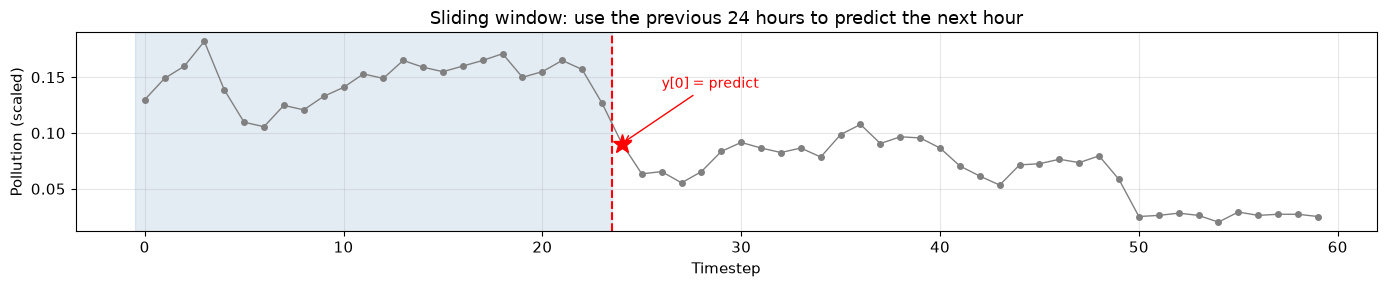

From 35,040 time steps → 35,016 training samples


In [12]:
# Visualize sliding window concept
fig, ax = plt.subplots(figsize=(14, 3))
sample = train_scaled[:60, 0]  # first 60 observations, pollution column
ax.plot(sample, 'o-', color='gray', markersize=4, linewidth=1)

# Window 1
ax.axvspan(-0.5, WINDOW_SIZE - 0.5, alpha=0.15, color='steelblue')
ax.annotate(f'X[0]\nwindow_size={WINDOW_SIZE}', xy=(WINDOW_SIZE//2, sample[WINDOW_SIZE//2]+0.05),
            ha='center', color='steelblue', fontsize=10, fontweight='bold')

# Target
ax.axvline(WINDOW_SIZE - 0.5, color='red', linestyle='--', linewidth=1.5)
ax.plot(WINDOW_SIZE, sample[WINDOW_SIZE], 'r*', markersize=14)
ax.annotate('y[0] = predict', xy=(WINDOW_SIZE, sample[WINDOW_SIZE]),
            xytext=(WINDOW_SIZE+2, sample[WINDOW_SIZE]+0.05),
            color='red', fontsize=10,
            arrowprops=dict(arrowstyle='->', color='red'))

ax.set_title(f'Sliding window: use the previous {WINDOW_SIZE} hours to predict the next hour')
ax.set_xlabel('Timestep')
ax.set_ylabel('Pollution (scaled)')
plt.tight_layout()
plt.show()

print(f'From {len(train_scaled):,} time steps → {len(X_train_uni):,} training samples')

> **Output explained:** The sliding-window figure highlights consecutive hours used to make a prediction. The window advances **one hour at a time**, reusing most of its previous observations. This increases the number of training examples without changing the original measurements.

In [13]:
class TimeSeriesDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)
    def __len__(self): return len(self.X)
    def __getitem__(self, idx): return self.X[idx], self.y[idx]

BATCH_SIZE = 64

# Important note:
# - DO NOT shuffle khi chia train/test.
# - Once windows are created within TRAIN, those independent samples may be shuffled in mini-batches,
#   because each window already contains its own known past context.
train_loader_uni   = DataLoader(TimeSeriesDataset(X_train_uni, y_train_uni), batch_size=BATCH_SIZE, shuffle=True)
test_loader_uni    = DataLoader(TimeSeriesDataset(X_test_uni,  y_test_uni),  batch_size=BATCH_SIZE, shuffle=False)
train_loader_multi = DataLoader(TimeSeriesDataset(X_train_multi, y_train_multi), batch_size=BATCH_SIZE, shuffle=True)
test_loader_multi  = DataLoader(TimeSeriesDataset(X_test_multi,  y_test_multi),  batch_size=BATCH_SIZE, shuffle=False)

# Inverse transform: convert scaled pollution back to µg/m³
# Because the scaler was fitted on all features, create a dummy matrix and replace the target column.
def inverse_pollution(scaled_values: np.ndarray) -> np.ndarray:
    scaled_values = np.asarray(scaled_values).reshape(-1)
    dummy = np.zeros((len(scaled_values), len(MULTI_COLS)))
    dummy[:, 0] = scaled_values
    return scaler.inverse_transform(dummy)[:, 0]

print('DataLoaders ready.')


DataLoaders ready.


> **Output explained:** `DataLoaders ready` means the sequences have been converted into PyTorch tensors and organized into batches. The model can now train on many 24-hour examples efficiently. The inverse-scaling helper later converts forecasts back to real pollution units (µg/m³).

---
## Phase C — RNN, LSTM, and BiLSTM

In [14]:
# Results table — updated after each model
results = {}

def show_results():
    if not results: print('No results yet.'); return
    df_r = pd.DataFrame(results, index=['MAE (μg/m³)', 'RMSE (μg/m³)']).T.round(2)
    print(df_r.to_string())

def train_model(model, train_loader, n_epochs=30, lr=1e-3):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()
    history = []
    for epoch in range(n_epochs):
        model.train()
        epoch_loss = 0
        for Xb, yb in train_loader:
            Xb, yb = Xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = criterion(model(Xb), yb)
            loss.backward()
            opt.step()
            epoch_loss += loss.item()
        avg = epoch_loss / len(train_loader)
        history.append(avg)
        if (epoch + 1) % 10 == 0:
            print(f'  Epoch {epoch+1:3d}/{n_epochs} | Loss: {avg:.5f}')
    return history

def evaluate_model(model, test_loader, name):
    model.eval()

    preds = []
    actuals = []

    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            y_pred = model(X_batch)

            preds.extend(y_pred.cpu().numpy().ravel())
            actuals.extend(y_batch.cpu().numpy().ravel())

    preds_r = inverse_pollution(np.array(preds))
    actuals_r = inverse_pollution(np.array(actuals))

    mae = mean_absolute_error(actuals_r, preds_r)
    rmse_value = rmse(actuals_r, preds_r)

    results[name] = [mae, rmse_value]

    print(f'{name}: MAE={mae:.2f}  RMSE={rmse_value:.2f}')

    return preds_r, actuals_r

> **What this code does:** `train_model` repeatedly updates model parameters using **Adam** and **MSE loss**; `evaluate_model` predicts on the test set, converts predictions back to pollution units, computes MAE/RMSE, and saves results in a shared table. Training loss and test error are different measurements: low training loss alone does not prove good future predictions.

### Step 5a — Naive forecasting and SimpleRNN

**Naive forecast:** Assume the next pollution value equals the most recent one. This is a strong baseline for slowly changing series.

**SimpleRNN:** Reads observations in time order and updates a memory-like hidden state after each hour. It can learn patterns, but it may struggle to remember information from many time steps earlier.

In [15]:
# Naive forecast: predict t+1 = t
# This is the minimum baseline.
# If the model does not beat naive, it has not improved on simply repeating the last value.

actuals_r = inverse_pollution(y_test_uni)
naive_preds = inverse_pollution(X_test_uni[:, -1, 0])  # last time step of the window

mae_n  = mean_absolute_error(actuals_r, naive_preds)
rmse_n = rmse(actuals_r, naive_preds)

results['Naive (y_t+1=y_t)'] = [mae_n, rmse_n]
print(f'Naive: MAE={mae_n:.2f}  RMSE={rmse_n:.2f}')
show_results()

Naive: MAE=12.43  RMSE=24.53
                   MAE (μg/m³)  RMSE (μg/m³)
Naive (y_t+1=y_t)        12.43         24.53


> **Output explained:** The naive forecast gets **MAE 12.43** and **RMSE 24.53 µg/m³** on the sequence-based test set. This is the benchmark to beat. The value differs very slightly from the earlier naive calculation because this evaluation starts after building complete 24-hour test windows.

In [16]:
class SimpleRNNModel(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=1):
        super().__init__()
        self.rnn = nn.RNN(input_size=input_size, hidden_size=hidden_size,
                          num_layers=num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])  # many-to-one: use the final time step

rnn_model = SimpleRNNModel(input_size=1)
print(f'SimpleRNN params: {sum(p.numel() for p in rnn_model.parameters()):,}')
print('Training...')
train_model(rnn_model, train_loader_uni, n_epochs=30)
rnn_preds, actuals_r = evaluate_model(rnn_model, test_loader_uni, 'SimpleRNN (uni)')

show_results()

SimpleRNN params: 4,353
Training...


  Epoch  10/30 | Loss: 0.00082


  Epoch  20/30 | Loss: 0.00081


  Epoch  30/30 | Loss: 0.00080
SimpleRNN (uni): MAE=14.26  RMSE=25.34
                   MAE (μg/m³)  RMSE (μg/m³)
Naive (y_t+1=y_t)        12.43         24.53
SimpleRNN (uni)          14.26         25.34


> **Output explained:** The SimpleRNN has **4,353 trainable parameters**. Its training loss falls to about **0.00080** in scaled units by epoch 30, but test performance is **MAE 14.26 / RMSE 25.34**. Both are **worse than naive**. This demonstrates why lowering training loss is not enough: we must compare forecasts on unseen data.

### Step 5b — Why can SimpleRNN struggle?

When a neural network trains, **backpropagation** sends an error signal backward through its computations. In an RNN this signal travels through many time steps; repeated multiplication by small values may cause it to shrink (**vanishing gradients**).

For example:

```text
0.9^24 ≈ 0.08       Only ~8% of the signal remains
0.7^24 ≈ 0.00019    Almost none remains
```

This makes some long-range patterns harder to learn. However, the window here is only 24 hours, so vanishing gradients are **not necessarily the reason** a SimpleRNN performs poorly. The naive baseline is already strong, and pollution spikes are difficult to predict.

### Step 6 — LSTM: an RNN with more controlled memory

LSTM means **Long Short-Term Memory**. It has a *cell state* that can carry useful information across time. Three gates control it:

| Gate | Simple meaning |
|---|---|
| **Forget gate** | Decide what old information to discard. |
| **Input gate** | Decide what new information to store. |
| **Output gate** | Decide what remembered information to use. |

An LSTM might learn to remember a rising pollution trend while ignoring brief irrelevant changes. This notebook uses two LSTM layers, 64 hidden units, and dropout of 0.2.

In [17]:
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=2, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )
        self.fc = nn.Linear(hidden_size, 1)
    def forward(self, x):
        # out   : (batch, seq_len, hidden_size)
        # h_n   : (num_layers, batch, hidden_size) — last hidden state of each layer
        # c_n   : (num_layers, batch, hidden_size) — last cell state of each layer
        out, (h_n, c_n) = self.lstm(x)
        return self.fc(out[:, -1, :])  # many-to-one

lstm_uni = LSTMModel(input_size=1)
print(f'LSTM params: {sum(p.numel() for p in lstm_uni.parameters()):,}')
print('Training LSTM univariate...')
train_model(lstm_uni, train_loader_uni, n_epochs=30)
lstm_uni_preds, actuals_r = evaluate_model(lstm_uni, test_loader_uni, 'LSTM (uni)')

show_results()

LSTM params: 50,497
Training LSTM univariate...


  Epoch  10/30 | Loss: 0.00085


  Epoch  20/30 | Loss: 0.00077


  Epoch  30/30 | Loss: 0.00073
LSTM (uni): MAE=12.22  RMSE=23.44
                   MAE (μg/m³)  RMSE (μg/m³)
Naive (y_t+1=y_t)        12.43         24.53
SimpleRNN (uni)          14.26         25.34
LSTM (uni)               12.22         23.44


> **Output explained:** The LSTM has **50,497 parameters**, far more than SimpleRNN. Its loss reaches about **0.00073** at epoch 30, and test errors are **MAE 12.22 / RMSE 23.44**. It beats both SimpleRNN and the naive baseline on these saved results, suggesting its memory mechanism captures some additional useful information.

### Step 7 — BiLSTM: reading the known sequence in two directions

A **Bidirectional LSTM (BiLSTM)** uses one LSTM from oldest to newest and another from newest to oldest. It joins what both learned.

**Is this using the future?** Not here. The input is `[t-23, ..., t]` and the target is `t+1`. Every input hour is already known when predicting the next hour, regardless of the reading direction.

**Data leakage would happen** if the input included values at `t+1` or later.

BiLSTM can be useful for analyzing complete sequences and can also be used with past-only windows for forecasting. For a continuously updating production forecast, a forward-only LSTM is often simpler and more naturally causal.

In [18]:
class BiLSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=2, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0
        )
        self.fc = nn.Linear(hidden_size * 2, 1)  # forward hidden + backward hidden

    def forward(self, x):
        # h_n shape when bidirectional=True:
        # (num_layers * 2, batch, hidden_size)
        # At the final layer:
        #   h_n[-2] = last forward hidden state
        #   h_n[-1] = last backward hidden state
        out, (h_n, c_n) = self.lstm(x)
        h_forward = h_n[-2]
        h_backward = h_n[-1]
        h = torch.cat([h_forward, h_backward], dim=1)
        return self.fc(h)

bilstm_uni = BiLSTMModel(input_size=1)
print(f'BiLSTM params: {sum(p.numel() for p in bilstm_uni.parameters()):,}')
print('Training BiLSTM univariate...')
train_model(bilstm_uni, train_loader_uni, n_epochs=30)
bilstm_uni_preds, _ = evaluate_model(bilstm_uni, test_loader_uni, 'BiLSTM (uni)')

show_results()


BiLSTM params: 133,761
Training BiLSTM univariate...


  Epoch  10/30 | Loss: 0.00083


  Epoch  20/30 | Loss: 0.00074


  Epoch  30/30 | Loss: 0.00071


BiLSTM (uni): MAE=12.60  RMSE=23.62
                   MAE (μg/m³)  RMSE (μg/m³)
Naive (y_t+1=y_t)        12.43         24.53
SimpleRNN (uni)          14.26         25.34
LSTM (uni)               12.22         23.44
BiLSTM (uni)             12.60         23.62


> **Output explained:** The BiLSTM has **133,761 parameters** and ends with training loss around **0.00071**. Test errors are **MAE 12.60 / RMSE 23.62**. It improves on naive by RMSE but not MAE, and it does **not** beat the univariate LSTM. Being more complex does not guarantee better performance.

---
## Phase D — Multivariate forecasting

### Step 8 — Add weather information

Previously, each hour included only pollution. Now each input hour contains **10 features**: pollution, dew point, temperature, pressure, wind speed, snow, rain, and three encoded wind-direction features.

The model class and training loop stay almost the same; only `input_size` changes.

**Question to test:** Do the weather features improve predictions? The earlier correlations were fairly weak, so improvement is possible but not guaranteed.

In [19]:
n_features = len(MULTI_COLS)
lstm_multi = LSTMModel(input_size=n_features)
print(f'Input: {n_features} features — {MULTI_COLS}')
print(f'Params: {sum(p.numel() for p in lstm_multi.parameters()):,}')
print('Training LSTM multivariate...')
train_model(lstm_multi, train_loader_multi, n_epochs=30)
lstm_multi_preds, _ = evaluate_model(lstm_multi, test_loader_multi, 'LSTM (multi)')

show_results()

print()
print('📝 Exercise: Train a multivariate BiLSTM and add it to the results table.')
print('   Hint: BiLSTMModel(input_size=n_features) + train_loader_multi')
print('   Solution at the end of the notebook.')


Input: 10 features — ['pollution', 'dew', 'temp', 'press', 'wnd_spd', 'snow', 'rain', 'wind_sin', 'wind_cos', 'wind_is_cv']
Params: 52,801
Training LSTM multivariate...


  Epoch  10/30 | Loss: 0.00082


  Epoch  20/30 | Loss: 0.00074


  Epoch  30/30 | Loss: 0.00068


LSTM (multi): MAE=12.38  RMSE=23.20
                   MAE (μg/m³)  RMSE (μg/m³)
Naive (y_t+1=y_t)        12.43         24.53
SimpleRNN (uni)          14.26         25.34
LSTM (uni)               12.22         23.44
BiLSTM (uni)             12.60         23.62
LSTM (multi)             12.38         23.20

📝 Exercise: Train a multivariate BiLSTM and add it to the results table.
   Hint: BiLSTMModel(input_size=n_features) + train_loader_multi
   Solution at the end of the notebook.


> **Output explained:** The multivariate LSTM uses **10 features** and **52,801 parameters**. Its saved scores are **MAE 12.38 / RMSE 23.20**. Compared with the univariate LSTM (**12.22 / 23.44**), average absolute error becomes slightly **worse**, but RMSE becomes **better**. This suggests weather inputs may help reduce some larger errors without consistently improving every hourly prediction.

---
## Phase E — Evaluation and conclusions

### Step 9 — Compare errors and study mistakes

- **MAE (Mean Absolute Error)**: the average size of a prediction mistake. An MAE of 12 means predictions miss by about 12 µg/m³ on average.
- **RMSE (Root Mean Squared Error)**: also measures error, but penalizes larger mistakes more heavily.
- **Residual** = actual − predicted. Positive residuals mean the model predicted too low.

For both MAE and RMSE, **lower is better**. Check the comparison chart, the predicted-versus-actual plot, and residual plots to see not just *how large* errors are but *when* they happen.

=== MODEL COMPARISON ===
                   MAE (μg/m³)  RMSE (μg/m³)
Naive (y_t+1=y_t)        12.43         24.53
SimpleRNN (uni)          14.26         25.34
LSTM (uni)               12.22         23.44
BiLSTM (uni)             12.60         23.62
LSTM (multi)             12.38         23.20


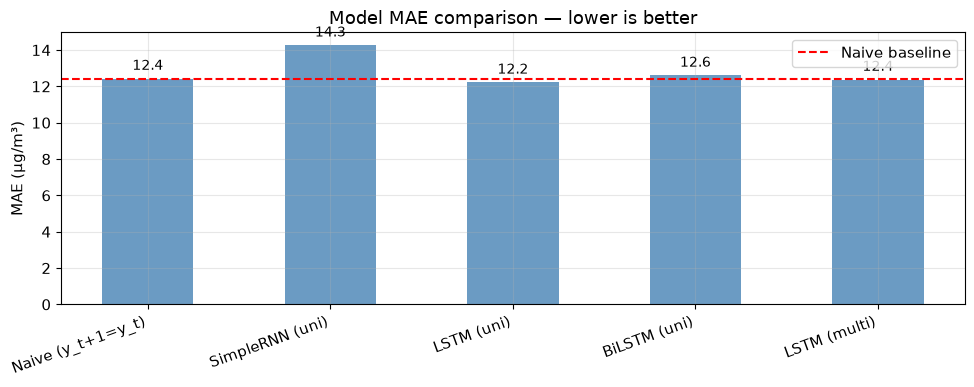


How to read the table:
- Naive is the baseline to beat.
- If a model does not beat naive, it adds no clear benefit for one-step forecasting.
- If multivariate lowers RMSE but not MAE, extra features may reduce large errors without consistent gains.
- Do not claim that deep learning is better unless the scores support it.


In [20]:
print('=== MODEL COMPARISON ===')
show_results()

df_r = pd.DataFrame(results, index=['MAE', 'RMSE']).T

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(df_r))
bars = ax.bar(x, df_r['MAE'], width=0.5, color='steelblue', alpha=0.8)
ax.axhline(df_r.loc['Naive (y_t+1=y_t)', 'MAE'], color='red',
           linestyle='--', linewidth=1.5, label='Naive baseline')
ax.set_xticks(x)
ax.set_xticklabels(df_r.index, rotation=20, ha='right')
ax.set_ylabel('MAE (μg/m³)')
ax.set_title('Model MAE comparison — lower is better')
ax.legend()
for bar, val in zip(bars, df_r['MAE']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{val:.1f}', ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.show()

print()
print('How to read the table:')
print('- Naive is the baseline to beat.')
print('- If a model does not beat naive, it adds no clear benefit for one-step forecasting.')
print('- If multivariate lowers RMSE but not MAE, extra features may reduce large errors without consistent gains.')
print('- Do not claim that deep learning is better unless the scores support it.')

> **Output explained:** This summary chart compares the five models trained so far (the exercise solution adds a sixth later). **Lower bars mean lower MAE**; the horizontal line marks the naive baseline. Among these five, univariate LSTM has the lowest MAE (**12.22**) while multivariate LSTM has the lowest RMSE (**23.20**). Don't choose a winner from MAE alone if extreme misses also matter.

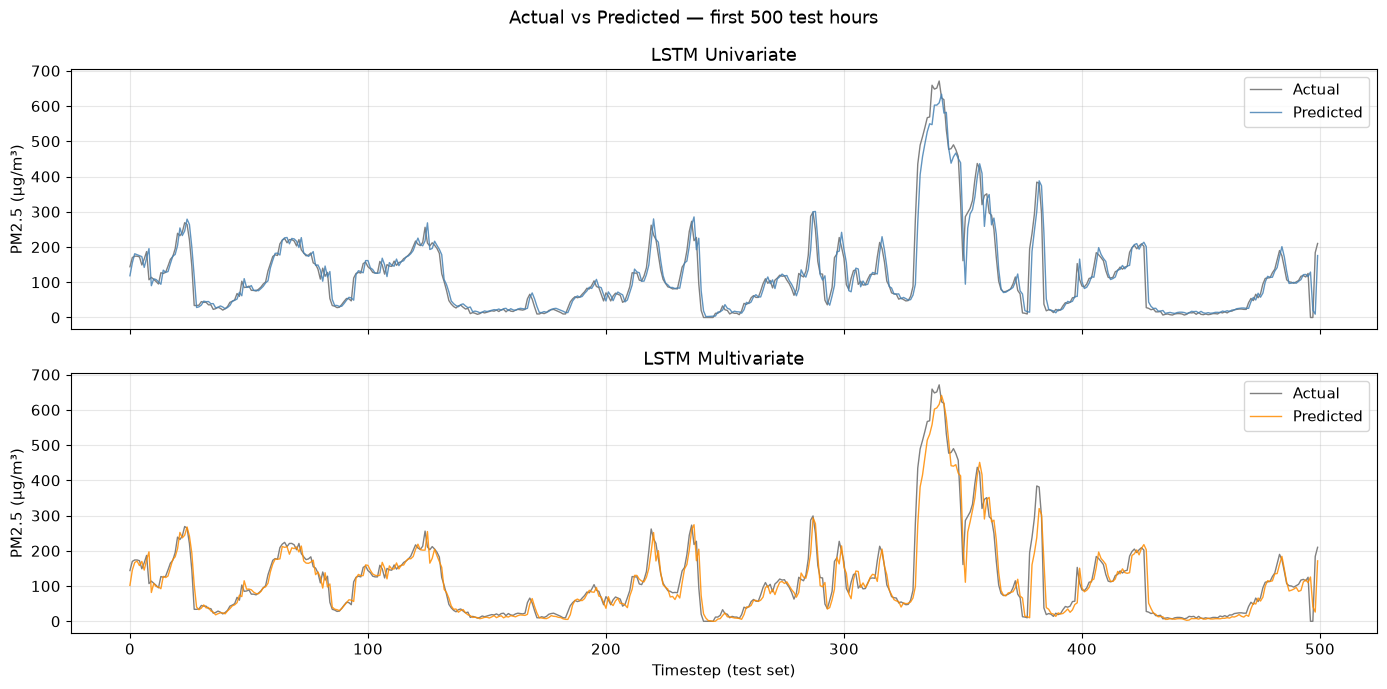

In [21]:
# Actual vs Predicted
N = 500  # first 500 test hours
actuals_r = inverse_pollution(y_test_uni)

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, preds, name, color in [
    (axes[0], lstm_uni_preds,   'LSTM Univariate',   'steelblue'),
    (axes[1], lstm_multi_preds, 'LSTM Multivariate', 'darkorange')
]:
    ax.plot(actuals_r[:N], label='Actual', linewidth=1, color='gray')
    ax.plot(preds[:N], label=f'Predicted', linewidth=1, alpha=0.85, color=color)
    ax.set_title(name)
    ax.set_ylabel('PM2.5 (μg/m³)')
    ax.legend(loc='upper right')
axes[1].set_xlabel('Timestep (test set)')
plt.suptitle('Actual vs Predicted — first 500 test hours', fontsize=13)
plt.tight_layout()
plt.show()

> **Output explained:** The plots overlay **actual pollution** and forecasts for the first **500 test hours**. Look for whether the models follow gradual changes and whether they lag behind sudden spikes. A line that looks smooth may still have poor MAE if it regularly misses sharp jumps. Use the numerical metrics together with these plots.

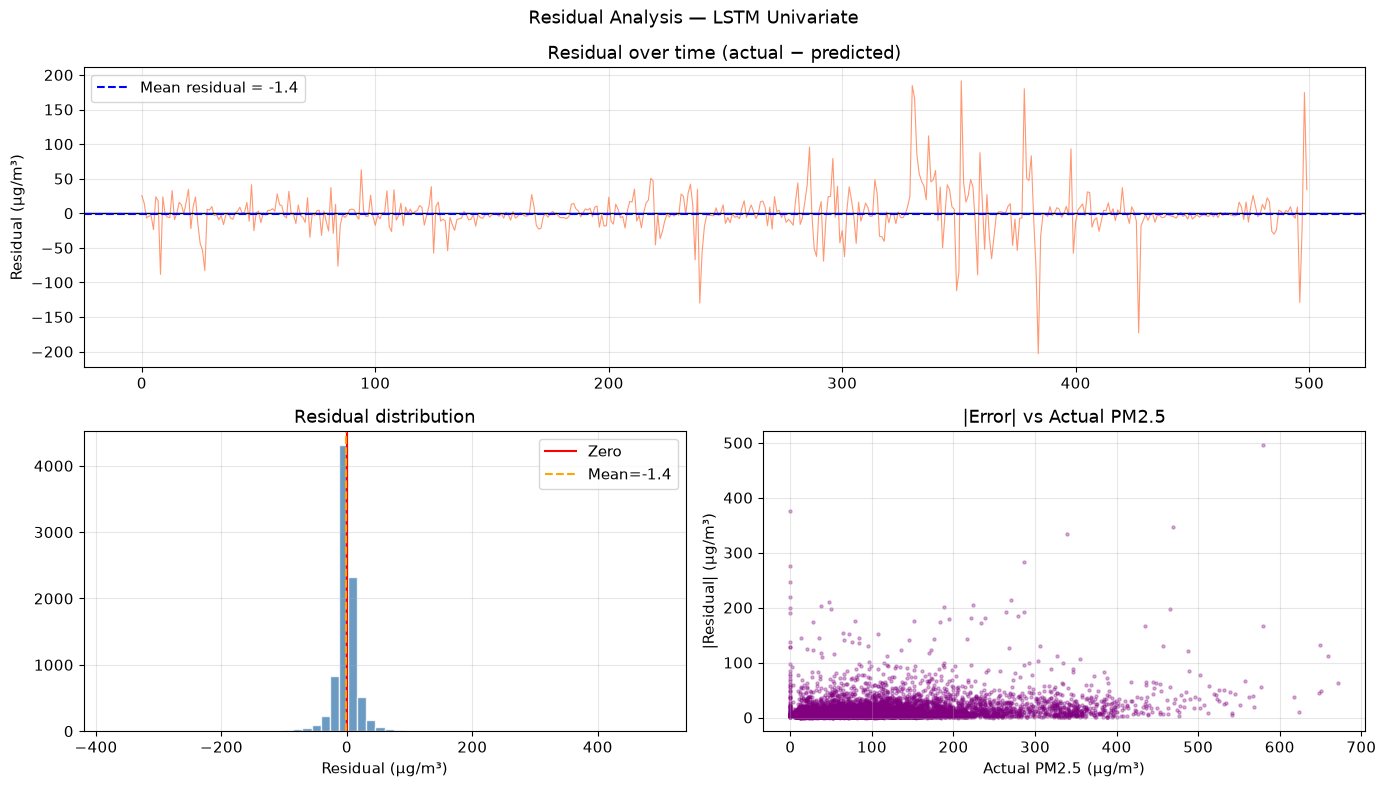

Overall MAE            : 12.22 μg/m³
MAE during spikes (top 10%) : 24.16 μg/m³
Spike threshold            : > 220 μg/m³

Interpretation:
- Positive residual skew suggests underprediction at high pollution levels
- Error during pollution spikes is much larger than overall MAE
- Possible improvement: try Huber loss or weighted sampling for extreme values


In [22]:
# Residual analysis — LSTM Univariate
residuals = actuals_r[:len(lstm_uni_preds)] - lstm_uni_preds
N = 500

fig = plt.figure(figsize=(14, 8))
gs = GridSpec(2, 2, figure=fig)

# 1. Residuals over time
# Patterns may indicate the model has missed useful signals.
# More random errors may indicate main patterns were captured.
ax1 = fig.add_subplot(gs[0, :])
ax1.plot(residuals[:N], linewidth=0.8, color='coral', alpha=0.8)
ax1.axhline(0, color='black', linewidth=1)
ax1.axhline(residuals.mean(), color='blue', linewidth=1.5, linestyle='--',
            label=f'Mean residual = {residuals.mean():.1f}')
ax1.set_title('Residual over time (actual − predicted)')
ax1.set_ylabel('Residual (μg/m³)')
ax1.legend()

# 2. Residual distribution
# Positive skew can mean underprediction of high pollution.
ax2 = fig.add_subplot(gs[1, 0])
ax2.hist(residuals, bins=60, color='steelblue', alpha=0.8, edgecolor='white')
ax2.axvline(0, color='red', linewidth=1.5, label='Zero')
ax2.axvline(residuals.mean(), color='orange', linewidth=1.5, linestyle='--',
            label=f'Mean={residuals.mean():.1f}')
ax2.set_title('Residual distribution')
ax2.set_xlabel('Residual (μg/m³)')
ax2.legend()

# 3. |Error| vs actual — where are mistakes largest?
# If error increases with actual pollution, spikes may be underpredicted.
ax3 = fig.add_subplot(gs[1, 1])
ax3.scatter(actuals_r[:len(residuals)], np.abs(residuals),
            alpha=0.3, s=5, color='purple')
ax3.set_title('|Error| vs Actual PM2.5')
ax3.set_xlabel('Actual PM2.5 (μg/m³)')
ax3.set_ylabel('|Residual| (μg/m³)')

plt.suptitle('Residual Analysis — LSTM Univariate', fontsize=13)
plt.tight_layout()
plt.show()

# Quantify spike failure
spike_thresh = np.percentile(actuals_r, 90)  # top 10% pollution events
spike_mask = actuals_r[:len(residuals)] > spike_thresh
print(f'Overall MAE            : {np.abs(residuals).mean():.2f} μg/m³')
print(f'MAE during spikes (top 10%) : {np.abs(residuals[spike_mask]).mean():.2f} μg/m³')
print(f'Spike threshold            : > {spike_thresh:.0f} μg/m³')
print()
print('Interpretation:')
print('- Positive residual skew suggests underprediction at high pollution levels')
print('- Error during pollution spikes is much larger than overall MAE')
print('- Possible improvement: try Huber loss or weighted sampling for extreme values')

> **Output explained:** The top graph shows errors over time; the histogram shows whether errors center around zero or have a long tail; the scatterplot shows whether error size increases at higher actual pollution. In the saved run, the univariate LSTM has **overall MAE 12.22**, but **MAE 24.16** during the top 10% pollution hours (**above 220 µg/m³**). Errors during spikes are almost twice as large. Positive residuals (actual − predicted) indicate underprediction. The suggested next experiments are Huber loss or putting more training emphasis on extreme events; neither improvement is guaranteed.

### Step 10 — Practical conclusions

| Model | Strength | Limitation |
|---|---|---|
| **SimpleRNN** | Small, easy to understand | May miss complex or longer-term patterns |
| **LSTM** | Better memory control | More parameters and training effort |
| **BiLSTM** | Uses both directions inside the known window | More complex and requires careful input design |

**What the saved results show:** BiLSTM with multiple features has the lowest MAE (**12.09 µg/m³**), while multivariate LSTM has the lowest RMSE (**23.20 µg/m³**). The gains over the naive forecast are relatively small. The SimpleRNN is worse than naive on both metrics.

**Key lesson:** Deep learning does not automatically beat a baseline. Compare models on unseen, chronologically later data.

**Caution:** This teaching notebook has a training/test split but no separate validation period. In a serious experiment, use chronologically ordered train/validation/test sets or walk-forward validation for tuning. Results can change between training runs.

---
### Exercise solution — Multivariate BiLSTM

Train the BiLSTM on all ten features, then add it to the same evaluation table.

In [23]:
bilstm_multi = BiLSTMModel(input_size=len(MULTI_COLS))
print(f'BiLSTM multi params: {sum(p.numel() for p in bilstm_multi.parameters()):,}')
print('Training BiLSTM multivariate...')
train_model(bilstm_multi, train_loader_multi, n_epochs=30)
evaluate_model(bilstm_multi, test_loader_multi, 'BiLSTM (multi)')
print()
print('=== FINAL MODEL RESULTS ===')
show_results()

BiLSTM multi params: 138,369
Training BiLSTM multivariate...


  Epoch  10/30 | Loss: 0.00079


  Epoch  20/30 | Loss: 0.00069


  Epoch  30/30 | Loss: 0.00066


BiLSTM (multi): MAE=12.09  RMSE=23.54

=== FINAL MODEL RESULTS ===
                   MAE (μg/m³)  RMSE (μg/m³)
Naive (y_t+1=y_t)        12.43         24.53
SimpleRNN (uni)          14.26         25.34
LSTM (uni)               12.22         23.44
BiLSTM (uni)             12.60         23.62
LSTM (multi)             12.38         23.20
BiLSTM (multi)           12.09         23.54


> **Output explained:** The multivariate BiLSTM has **138,369 parameters**. Its training loss reaches about **0.00066**, and test scores are **MAE 12.09 / RMSE 23.54**. Across all six evaluated approaches it has the **lowest MAE**, whereas the **multivariate LSTM has the lowest RMSE (23.20)**. Choose based on which type of error matters most; neither network wins both metrics.